# Biology: where does shortening change retrieval?

Updated notebook

Run every Biology query against the full corpus with BM25 and Qwen3-Embedding-4B. Generate one response per question, then hold it fixed across the text ablations. The final table shows where keeping more text helps and where it hurts.

Use Colab GPU runtime. Upload `study.py` to the runtime's Files panel before running (available in teh github), add `IDA_LLM_API_KEY` under Secrets. The helper contains shared data, generation and retrieval code used by various nbs. Restart session after installing packages if Colab has already imported older versions.


In [1]:
%pip -q install "pyterrier[all]" openai datasets sentence-transformers accelerate matplotlib


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 947.8/947.8 kB 16.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.3/61.3 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 58.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 304.9/304.9 kB 23.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 223.1/223.1 kB 10.1 MB/s eta 0:00:00


## Choose the run

The defaults use all Biology questions (103 of them). Keep generation prompt and model fixed. Batch sizes can change within a run. Change output folder when changing the config, completed responses are reused within a run. Corpus embeddings are the only large persistent cache. The BM25 index stays on the runtime's local disk.

R5 Qwen wrapper defaults to 2048 tokens. We allow 16384 and check lengths before encoding. Start with batch size 1 for long queries and 4 for passages; increase only after checking GPU memory.


In [3]:
import json
import importlib.metadata
from pathlib import Path
import numpy as np
import pandas as pd
import pyterrier as pt
from google.colab import drive, userdata
from openai import OpenAI
from transformers import AutoTokenizer
from IPython.display import display
import study as s

drive.mount('/content/drive')
ROOT = Path('/content/drive/MyDrive/diss_biology')
ROOT.mkdir(parents=True, exist_ok=True)
PROMPT = """{query}

Instructions:
1. Identify the essential problem.
2. Reason through what information could be relevant and helpful to address the question in detail.
3. Draft a candidate answer, explaining the concepts and steps needed.
"""
config = dict(
    dataset_revision='3066d29c9651a576c8aba4832d249807b181ecae',
    model='deepseek-r1-distil-qwen-14b', base_url='http://api.terrier.org/v1',
    tokenizer='deepseek-ai/DeepSeek-R1-Distill-Qwen-14B',
    tokenizer_revision='1df8507178afcc1bef68cd8c393f61a886323761',
    max_new_tokens=8192, temperature=0.6, top_p=0.95, prompt=PROMPT,
    embedding_model='Qwen/Qwen3-Embedding-4B', max_length=16384,
    doc_batch_size=1, query_batch_size=1,
    bm25_controls={'bm25.k_1': '1.2', 'bm25.b': '0.75', 'bm25.k_3': '8'})

config_path = ROOT / 'config.json'

if config_path.exists():
    previous = json.loads(config_path.read_text())
    for key in ['doc_batch_size', 'query_batch_size']:
        previous[key] = config[key]  # Batch sizes can change without invalidating the experiment.
    assert previous == config, 'Choose a new ROOT for a changed scientific configuration.'

config_path.write_text(json.dumps(config, indent=2))
packages = ['pyterrier', 'openai', 'datasets', 'sentence-transformers', 'transformers', 'torch']
print({name: importlib.metadata.version(name) for name in packages})
tokenizer = AutoTokenizer.from_pretrained(config['tokenizer'], revision=config['tokenizer_revision'])
# using R5 code
queries, corpus, qrels = s.load_biology(config['dataset_revision'])
assert len(queries) == 103 and len(corpus) == 57359
print(len(queries), 'queries;', len(corpus), 'passages')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
{'pyterrier': '1.1.2', 'openai': '2.54.0', 'datasets': '4.8.5', 'sentence-transformers': '5.7.0', 'transformers': '5.18.0', 'torch': '2.11.0+cu130'}
103 queries; 57359 passages


## Generate once

Stores the raw response before checking that the generation finished and exposed both reasoning and an answer. If a response is incomplete, inspect it and use a new run with revised settings. No gold passages or reference answers enter the prompt.


In [4]:
client = OpenAI(base_url=config['base_url'], api_key=userdata.get('IDA_LLM_API_KEY'), max_retries=2)
traces = s.generate(queries, PROMPT, config, ROOT / 'responses.jsonl', client).set_index('qid')
display(traces[['reasoning', 'answer', 'seconds']].head(3))


,reasoning,answer,seconds
qid,,,
biology/0,"Okay, so I'm trying to figure out why the arti...",The article posits that insects are attracted ...,38.893592
biology/1,"Okay, so I just noticed that I'm only breathin...",The phenomenon of breathing predominantly thro...,31.947443
biology/2,"Okay, so I'm trying to figure out if there's a...","The concept of an RGB equivalent for smells, w...",47.835763


## Build inputs and retrievers

Each generated input replaces the original question. Prefixes change length, content and position together, so the reasoning-only and answer-only controls help explain their results. The token axis measures retrieval input length; these edits leave the original generation cost unchanged.

The dense retriever searches the full corpus. Both retrievers fetch enough candidates to remove BRIGHT's excluded documents before taking ten. Qwen uses FP16 and PyTorch SDPA on the T4. The loading and BRIGHT mappings follow R5, with my PyTerrier BM25 and SentenceTransformer encoding to keep the setup small.


In [5]:
rows = []
for row in queries.itertuples():
    trace = traces.loc[row.qid]
    full = trace.full_text
    inputs = {'original': row.query, 'full': full, 'reasoning': trace.reasoning, 'answer': trace.answer}
    for percent in [25, 50, 75]:
        inputs[f'prefix_{percent}'] = s.prefix(full, max(1, s.token_count(full, tokenizer) * percent // 100), tokenizer)
    rows.extend(dict(qid=row.qid, variant=name, text=text, tokens=s.token_count(text, tokenizer))
                for name, text in inputs.items())
variants = pd.DataFrame(rows)
assert len(variants) == 7 * len(queries)
# using R5 code
systems, encoder = s.retrievers(corpus, queries, config, ROOT)


Java started (triggered by tokenise) and loaded: pyterrier.java.colab, pyterrier.java, pyterrier.java.24, pyterrier.terrier.java [version=5.11 (build: craig.macdonald 2025-01-13 21:29), helper_version=0.0.8]


## Evaluate

`pt.Experiment` returns the mean and per-query nDCG@10 tables, on a 0 to 1 scale. Queries with no retrieved hits still count. We save the small score and top-ten tables so the later notebooks can inspect the same run without generating again.


In [6]:
means, per_query, rankings = s.evaluate(variants, systems, queries, qrels)
per_query.to_csv(ROOT / 'metrics.csv', index=False)
rankings.to_csv(ROOT / 'rankings.csv', index=False)
display(means)


,name,nDCG@10
0,BM25/original,0.090148
1,BM25/full,0.283214
2,BM25/reasoning,0.253261
3,BM25/answer,0.298129
4,BM25/prefix_25,0.195383
5,BM25/prefix_50,0.232201
6,BM25/prefix_75,0.271838


## Find the largest differences

The main contrast is full text minus the 50% prefix. Positive differences favour full text. Negative differences favour the prefix. Inspect both ends, the largest score ranges across all prefix lengths and the original query, and a few questions where the scores barely change. These selected examples explain effects; the full-dataset table shows their prevalence.


BM25 improved / tied / degraded: 39 52 12


,query,BM25_delta,BM25_vs_original,BM25_range
qid,,,,
biology/54,Is blood regarded as an organ?\nIt consist app...,-0.327234,0.471628,0.798861
biology/74,Why do birches have a white bark?\nSeveral spe...,-0.318341,-0.151020,0.318341
biology/96,How does the eye know whether to focus further...,-0.306574,0.129334,0.435908
biology/4,What is the evolutionary advantage of red-gree...,-0.192276,0.358534,0.550810
biology/55,Seeing strange things in light\nI have noticed...,-0.167160,0.000000,0.650821


,query,BM25_delta,BM25_vs_original,BM25_range
qid,,,,
biology/19,Is kissing a natural human activity?\nThe word...,0.500000,1.000000,1.000000
biology/94,Can a neuron make a synapse onto itself?\nI wa...,0.485663,0.441492,0.636682
biology/95,Are there grass or fiber eating birds?\nMy und...,0.463492,0.850345,0.850345
biology/16,Why does an electrical shock freeze up muscles...,0.430677,0.430677,0.500000
biology/6,Why does evolution not make our life longer?\n...,0.397672,0.617764,0.617764


,query,BM25_delta,BM25_vs_original,BM25_range
qid,,,,
biology/37,Why doesn't water enter my body through my anu...,0.122785,1.000000,1.000000
biology/26,How is temperature sensed?\nCan anyone summari...,0.000000,1.000000,1.000000
biology/19,Is kissing a natural human activity?\nThe word...,0.500000,1.000000,1.000000
biology/35,"Why does hair turn grey or white, and why does...",0.212523,0.965137,0.983303
biology/99,What creates the feeling of 'excess' blood pre...,0.000000,0.967468,0.967468


<Axes: xlabel='qid', ylabel='Full minus 50% prefix: nDCG@10'>

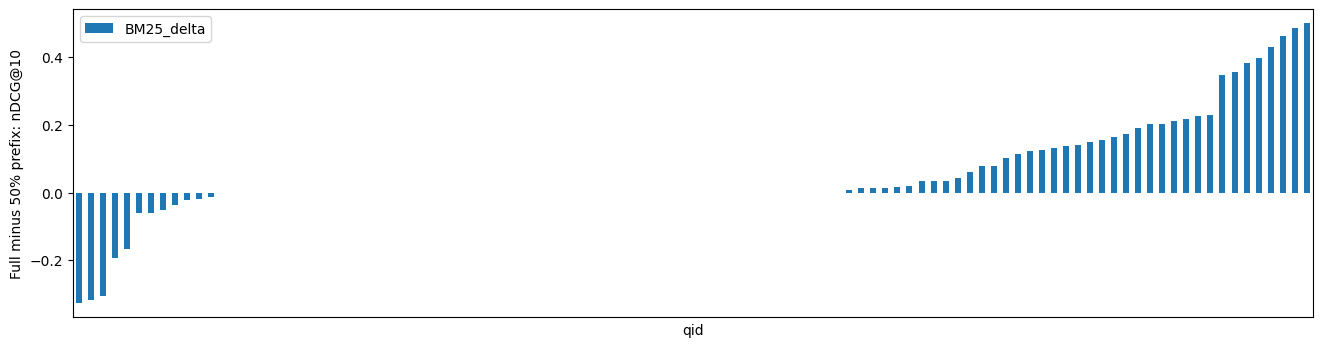

In [7]:
wide = per_query.pivot(index='qid', columns='name', values='value')
differences = queries[['qid', 'query']].set_index('qid').copy()
for model in systems:
    differences[f'{model}_delta'] = wide[f'{model}/full'] - wide[f'{model}/prefix_50']
    differences[f'{model}_vs_original'] = wide[f'{model}/full'] - wide[f'{model}/original']
    length_scores = wide[[f'{model}/{name}' for name in ['original', 'full', 'prefix_25', 'prefix_50', 'prefix_75']]]
    differences[f'{model}_range'] = length_scores.max(axis=1) - length_scores.min(axis=1)
    delta = differences[f'{model}_delta']
    print(model, 'improved / tied / degraded:', (delta > 0).sum(), (delta == 0).sum(), (delta < 0).sum())
    display(differences.sort_values(f'{model}_delta').head(5))
    display(differences.sort_values(f'{model}_delta', ascending=False).head(5))
    display(differences.sort_values(f'{model}_range', ascending=False).head(5))
differences.to_csv(ROOT / 'query_differences.csv')
differences[[f'{model}_delta' for model in systems]].sort_values('BM25_delta').plot.bar(
    figsize=(16, 4), ylabel='Full minus 50% prefix: nDCG@10', legend=True, xticks=[])


## Inspect one question

Use a query ID from the difference tables. Read its generated text and changed document ranks. Gold passages are available for diagnosis; keep them out of later generation and automatic selection rules.


In [8]:
READ_QID = differences.BM25_delta.abs().idxmax()
MODEL = 'BM25'
print('QUESTION:', queries.set_index('qid').loc[READ_QID, 'query'])
print('\nGENERATED TEXT:\n', traces.loc[READ_QID, 'full_text'])
lookup = corpus.set_index('docno').text
for name in [f'{MODEL}/full', f'{MODEL}/prefix_50']:
    print('\n', name)
    hits = rankings[(rankings.qid == READ_QID) & (rankings.name == name)].copy()
    hits['text'] = hits.docno.map(lookup)
    hits['relevant'] = hits.docno.isin(queries.set_index('qid').loc[READ_QID, 'gold_ids'])
    display(hits)


QUESTION: Is kissing a natural human activity?
The word natural here is meant in contrast to it being a sociological construct.
Is kissing in all its forms something natural for humans? Is it instinctively erotic? Or is it just a conventional form to show trust and intimicy, i.e. the association besically just comes via a social means?
Because the only other advantage of this mouth to mouth contact I could see is maybe for the immune system.

GENERATED TEXT:
 Okay, so I need to figure out whether kissing is a natural human activity or just a social construct. The user is asking if kissing is something instinctive or if it's just something we learn from society. They also mentioned that maybe it's related to the immune system, which I remember reading about somewhere.

First, I should break down the question. The main problem is determining if kissing is natural or a social construct. To do that, I need to consider biological, evolutionary, and sociocultural factors.

I'll start by thin

,qid,query_0,query,docid,docno,rank,score,name,text,relevant
1170,biology/19,"Okay, so I need to figure out whether kissing ...",okay so i need to figure out whether kissing i...,36401,kissing_natural_human_activity/Kiss_8.txt,0,26.793090,BM25/full,Biology and evolution[edit]\nBlack-tailed prai...,True
1171,biology/19,"Okay, so I need to figure out whether kissing ...",okay so i need to figure out whether kissing i...,36324,kissing_natural_human_activity/Kiss_0_0.txt,1,26.723225,BM25/full,A kiss is the touch or pressing of one's lips ...,False
1172,biology/19,"Okay, so I need to figure out whether kissing ...",okay so i need to figure out whether kissing i...,36466,kissing_natural_human_activity/Cheek_kissing_0...,2,25.490486,BM25/full,", alternating cheeks. Depending on country and...",False
1173,biology/19,"Okay, so I need to figure out whether kissing ...",okay so i need to figure out whether kissing i...,36417,kissing_natural_human_activity/Kiss_2_11.txt,3,25.386256,BM25/full,recent development and is rarely mentioned ev...,False
1174,biology/19,"Okay, so I need to figure out whether kissing ...",okay so i need to figure out whether kissing i...,36371,kissing_natural_human_activity/Kissing_traditi...,4,24.743579,BM25/full,"In Ecuador, women kiss on the right cheek onl...",False
1175,biology/19,"Okay, so I need to figure out whether kissing ...",okay so i need to figure out whether kissing i...,36351,kissing_natural_human_activity/Kiss_2_9.txt,5,24.143541,BM25/full,particularly in England.\nRomantic kiss[edit]...,False
1176,biology/19,"Okay, so I need to figure out whether kissing ...",okay so i need to figure out whether kissing i...,36462,kissing_natural_human_activity/Kiss_1_2.txt,6,24.047123,BM25/full,is no single point of origin in historical ti...,False
1177,biology/19,"Okay, so I need to figure out whether kissing ...",okay so i need to figure out whether kissing i...,36384,kissing_natural_human_activity/Kiss_5_0.txt,7,23.997533,BM25/full,Contemporary practices[edit]\nPrincess Madelei...,False
1178,biology/19,"Okay, so I need to figure out whether kissing ...",okay so i need to figure out whether kissing i...,36412,kissing_natural_human_activity/Kissing_traditi...,8,23.957618,BM25/full,\nMany societies have traditions which involve...,False
1179,biology/19,"Okay, so I need to figure out whether kissing ...",okay so i need to figure out whether kissing i...,36390,kissing_natural_human_activity/Air_kiss_1_0.txt,9,23.695682,BM25/full,Western culture[edit]\nFrancesco Totti blowing...,False



 BM25/prefix_50


,qid,query_0,query,docid,docno,rank,score,name,text,relevant
5290,biology/19,"Okay, so I need to figure out whether kissing ...",okay so i need to figure out whether kissing i...,36412,kissing_natural_human_activity/Kissing_traditi...,0,26.874472,BM25/prefix_50,\nMany societies have traditions which involve...,False
5291,biology/19,"Okay, so I need to figure out whether kissing ...",okay so i need to figure out whether kissing i...,36417,kissing_natural_human_activity/Kiss_2_11.txt,1,26.742718,BM25/prefix_50,recent development and is rarely mentioned ev...,False
5292,biology/19,"Okay, so I need to figure out whether kissing ...",okay so i need to figure out whether kissing i...,36401,kissing_natural_human_activity/Kiss_8.txt,2,26.267852,BM25/prefix_50,Biology and evolution[edit]\nBlack-tailed prai...,True
5293,biology/19,"Okay, so I need to figure out whether kissing ...",okay so i need to figure out whether kissing i...,36371,kissing_natural_human_activity/Kissing_traditi...,3,25.968903,BM25/prefix_50,"In Ecuador, women kiss on the right cheek onl...",False
5294,biology/19,"Okay, so I need to figure out whether kissing ...",okay so i need to figure out whether kissing i...,36460,kissing_natural_human_activity/French_kiss_1_1...,4,25.687553,BM25/prefix_50,"slow, passionate kiss which is considered int...",False
5295,biology/19,"Okay, so I need to figure out whether kissing ...",okay so i need to figure out whether kissing i...,36462,kissing_natural_human_activity/Kiss_1_2.txt,5,25.679931,BM25/prefix_50,is no single point of origin in historical ti...,False
5296,biology/19,"Okay, so I need to figure out whether kissing ...",okay so i need to figure out whether kissing i...,36351,kissing_natural_human_activity/Kiss_2_9.txt,6,25.211345,BM25/prefix_50,particularly in England.\nRomantic kiss[edit]...,False
5297,biology/19,"Okay, so I need to figure out whether kissing ...",okay so i need to figure out whether kissing i...,36375,kissing_natural_human_activity/Kiss_5_10.txt,7,24.864001,BM25/prefix_50,"Western cultures. A kiss can be ""blown"" to an...",False
5298,biology/19,"Okay, so I need to figure out whether kissing ...",okay so i need to figure out whether kissing i...,36390,kissing_natural_human_activity/Air_kiss_1_0.txt,8,24.625548,BM25/prefix_50,Western culture[edit]\nFrancesco Totti blowing...,False
5299,biology/19,"Okay, so I need to figure out whether kissing ...",okay so i need to figure out whether kissing i...,36338,kissing_natural_human_activity/Kiss_7_4.txt,9,24.448643,BM25/prefix_50,\nThe holy kiss or kiss of peace is a traditio...,False


## Findings

Qwen 4b did not work on colab

Using the LLM’s response as the search query retrieved more relevant passages than using the original question. The final answer alone performed best on average. Keeping the reasoning and answer together scored slightly lower, while keeping only the first 75% of the response came close to the full response. These results suggest we should test whether we can remove some text without hurting retrieval.

Full text beat the 50% prefix on 39 queries, tied on 52 and lost on 12. These cases should be inspected next:
- biology/19: Full text improved the score by 0.500 and moved the relevant passage from rank 3 to rank 1. The trace visibly repeats the biological/cultural distinction. Check whether later vocabulary or repeated terms explain the gain before deleting anything.
- biology/94 and /95, self-synapses and fibre-eating birds: Large gains from full text. Look for useful terms appearing later and test whether a shorter selection can retain them.
- biology/54, /74 and /96, blood, birch bark and eye focusing: The 50% prefix performed substantially better. Inspect the removed text for repetition, speculation or changes in emphasis. For /74, full text also performed worse than the original question.
- biology/55, strange things seen in light: A large score range across the variants. Compare all prefix lengths to locate where retrieval changes.
- biology/26 and /99: Full and 50% text tied despite strong gains over the original question. Use these as controls where shortening preserved the score.
Repetition is visible in /19, but deletion trials are still needed before using MMR. These results show which retrieval text helped; they do not establish that more reasoning computation helped.
